# Terrain de jeu : consommation énergétique de 7 sites (2023-2024)

Ce notebook explore le dataset horaire `all_sites_combined.csv` (7 sites, 17 521 heures chacun).

**Comment l'utiliser**
- Exécutez les cellules de haut en bas (*Run All*), puis modifiez les **réglages** de la section 3 (site, dates, seuil) et relancez les cellules suivantes.
- Prérequis : `pip install pandas matplotlib ipykernel` dans le venv, et ce venv sélectionné comme *kernel*.
- Aucun fichier n'est écrit : tout reste dans le notebook.

## 1. Chargement

Les fichiers csv doivent se trouver dans le dossier /data

In [2]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# --- Affichage -------------------------------------------------------------
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- Si le CSV n'est pas trouvé automatiquement, mettez son chemin ici -------
CSV_PATH = None   # exemple : r"C:\Users\...\ml\data\all_sites_combined.csv"


def trouver_fichier(nom):
    """Cherche un fichier par son nom dans le dossier courant, ses parents et leurs dossiers data/."""
    bases = [Path.cwd(), *list(Path.cwd().parents)[:3]]
    for base in bases:
        for sous in ("", "data", "ml/data"):
            dossier = base / sous
            if not dossier.is_dir():
                continue
            # recherche récursive uniquement dans les dossiers data/ (pas dans .venv)
            trouve = next(dossier.rglob(nom) if sous else dossier.glob(nom), None)
            if trouve:
                return trouve
    return None


chemin = Path(CSV_PATH) if CSV_PATH else trouver_fichier("all_sites_combined.csv")
if chemin is None or not chemin.exists():
    raise FileNotFoundError("all_sites_combined.csv introuvable : renseignez CSV_PATH ci-dessus.")

df = pd.read_csv(chemin, parse_dates=["timestamp"])
df = df.sort_values(["site_id", "timestamp"]).reset_index(drop=True)

print(f"Fichier : {chemin}")
print(f"{len(df):,} lignes, {df['site_id'].nunique()} sites, du {df['timestamp'].min()} au {df['timestamp'].max()}")
display(df.head())

Fichier : c:\Users\mboyadjian2024\Documents\GitHub\smart_energy_optimizer\ml\data\all_sites_combined.csv
122,647 lignes, 7 sites, du 2023-01-01 00:00:00 au 2024-12-31 00:00:00


,timestamp,site_id,site_type,site_name,consumption_kwh,consumption_euros,temperature_celsius,humidity_percent,solar_irradiance_wm2,hour,day_of_week,day_name,month,is_weekend,is_working_hours
0,2023-01-01 00:00:00,SITE001,office,Bureau Tertiaire,85.82,12.87,10.6,76.7,0.0,0,6,Sunday,1,1,0
1,2023-01-01 01:00:00,SITE001,office,Bureau Tertiaire,89.84,13.48,12.0,70.6,0.0,1,6,Sunday,1,1,0
2,2023-01-01 02:00:00,SITE001,office,Bureau Tertiaire,80.62,12.09,13.8,62.2,0.0,2,6,Sunday,1,1,0
3,2023-01-01 03:00:00,SITE001,office,Bureau Tertiaire,92.67,13.90,9.4,66.0,0.0,3,6,Sunday,1,1,0
4,2023-01-01 04:00:00,SITE001,office,Bureau Tertiaire,72.50,10.88,14.8,67.2,41.5,4,6,Sunday,1,1,0


Colonnes : `consumption_kwh` (consommation de l'heure), `consumption_euros` (coût), `temperature_celsius`, `humidity_percent`, `solar_irradiance_wm2` (ensoleillement), puis des colonnes calendaires (`hour`, `day_of_week`, `day_name`, `month`, `is_weekend`, `is_working_hours`).

## 2. Qualité des données

In [3]:
# --- Valeurs manquantes -------------------------------------------------------
colonnes_mesure = ["consumption_kwh", "consumption_euros", "temperature_celsius",
                   "humidity_percent", "solar_irradiance_wm2"]

print("% de valeurs manquantes par colonne :")
display(df[colonnes_mesure].isna().mean().mul(100).round(2).rename("% nuls").to_frame())

print("% de valeurs manquantes par site :")
display(df.groupby("site_id")[colonnes_mesure].apply(lambda g: g.isna().mean() * 100).round(1))

% de valeurs manquantes par colonne :


,% nuls
consumption_kwh,2.32
consumption_euros,2.03
temperature_celsius,2.79
humidity_percent,2.79
solar_irradiance_wm2,3.23


% de valeurs manquantes par site :


,consumption_kwh,consumption_euros,temperature_celsius,humidity_percent,solar_irradiance_wm2
site_id,,,,,
SITE001,2.3,2.1,2.8,2.8,3.2
SITE002,2.3,2.0,2.8,2.8,3.2
SITE003,2.3,2.0,2.8,2.8,3.3
SITE004,2.3,2.0,2.8,2.8,3.3
SITE005,2.3,2.0,2.8,2.8,3.2
SITE006,2.3,2.0,2.8,2.8,3.2
SITE007,2.3,2.0,2.7,2.7,3.2


In [4]:
# --- Les valeurs manquantes sont-elles isolées ou en blocs (pannes) ? ----------
def blocs_nuls(serie):
    """Longueur (en heures) de chaque série consécutive de valeurs manquantes."""
    est_nul = serie.isna()
    num_bloc = (est_nul != est_nul.shift()).cumsum()
    longueurs = est_nul.groupby(num_bloc).sum()
    return longueurs[longueurs > 0]

stats = {}
for site, g in df.groupby("site_id"):
    b = blocs_nuls(g["consumption_kwh"])
    stats[site] = {"nb de blocs": len(b), "durée médiane (h)": b.median(), "durée max (h)": b.max()}
display(pd.DataFrame(stats).T)

,nb de blocs,durée médiane (h),durée max (h)
SITE001,148.0,2.0,12.0
SITE002,156.0,1.0,11.0
SITE003,147.0,2.0,11.0
SITE004,143.0,2.0,8.0
SITE005,157.0,2.0,10.0
SITE006,147.0,2.0,8.0
SITE007,151.0,2.0,8.0


In [5]:
# --- Contrôles de cohérence ---------------------------------------------------
# 1) Trous ou doublons dans le calendrier horaire
ctrl = {}
for site, g in df.groupby("site_id"):
    attendu = pd.date_range(g["timestamp"].min(), g["timestamp"].max(), freq="h")
    ctrl[site] = {"heures manquantes": len(attendu.difference(g["timestamp"])),
                  "doublons": int(g["timestamp"].duplicated().sum())}
print("Calendrier horaire :")
display(pd.DataFrame(ctrl).T)

# 2) Prix du kWh : constant ?
prix = (df["consumption_euros"] / df["consumption_kwh"]).replace([np.inf, -np.inf], np.nan)
print("Prix implicite (euros / kWh) :")
display(prix.describe().round(3).to_frame("prix"))

# 3) Ensoleillement la nuit (devrait être nul)
nuit = df[df["hour"].isin([0, 1, 2, 3, 22, 23])]
print(f"Heures de nuit avec ensoleillement > 0 : {(nuit['solar_irradiance_wm2'] > 0).mean():.2%}  "
      f"(max = {nuit['solar_irradiance_wm2'].max():.0f} W/m2)")

# 4) Consommations nulles ou négatives
print(f"Consommation = 0 : {(df['consumption_kwh'] == 0).sum()} heures | < 0 : {(df['consumption_kwh'] < 0).sum()} heures")

Calendrier horaire :


,heures manquantes,doublons
SITE001,0,0
SITE002,0,0
SITE003,0,0
SITE004,0,0
SITE005,0,0
SITE006,0,0
SITE007,0,0


Prix implicite (euros / kWh) :


,prix
count,118015.00
mean,0.15
std,0.00
min,0.15
25%,0.15
50%,0.15
75%,0.15
max,0.15


Heures de nuit avec ensoleillement > 0 : 48.39%  (max = 208 W/m2)
Consommation = 0 : 1792 heures | < 0 : 0 heures


## 3. Réglages (à modifier puis relancer les cellules suivantes)

In [8]:
DEBUT = "2023-01-01"      # période étudiée
FIN = "2024-12-31"
SEUIL_Z = 4.0             # sensibilité de la détection d'anomalies (section 7) : plus grand = moins d'alertes

## 4. Consommation dans le temps

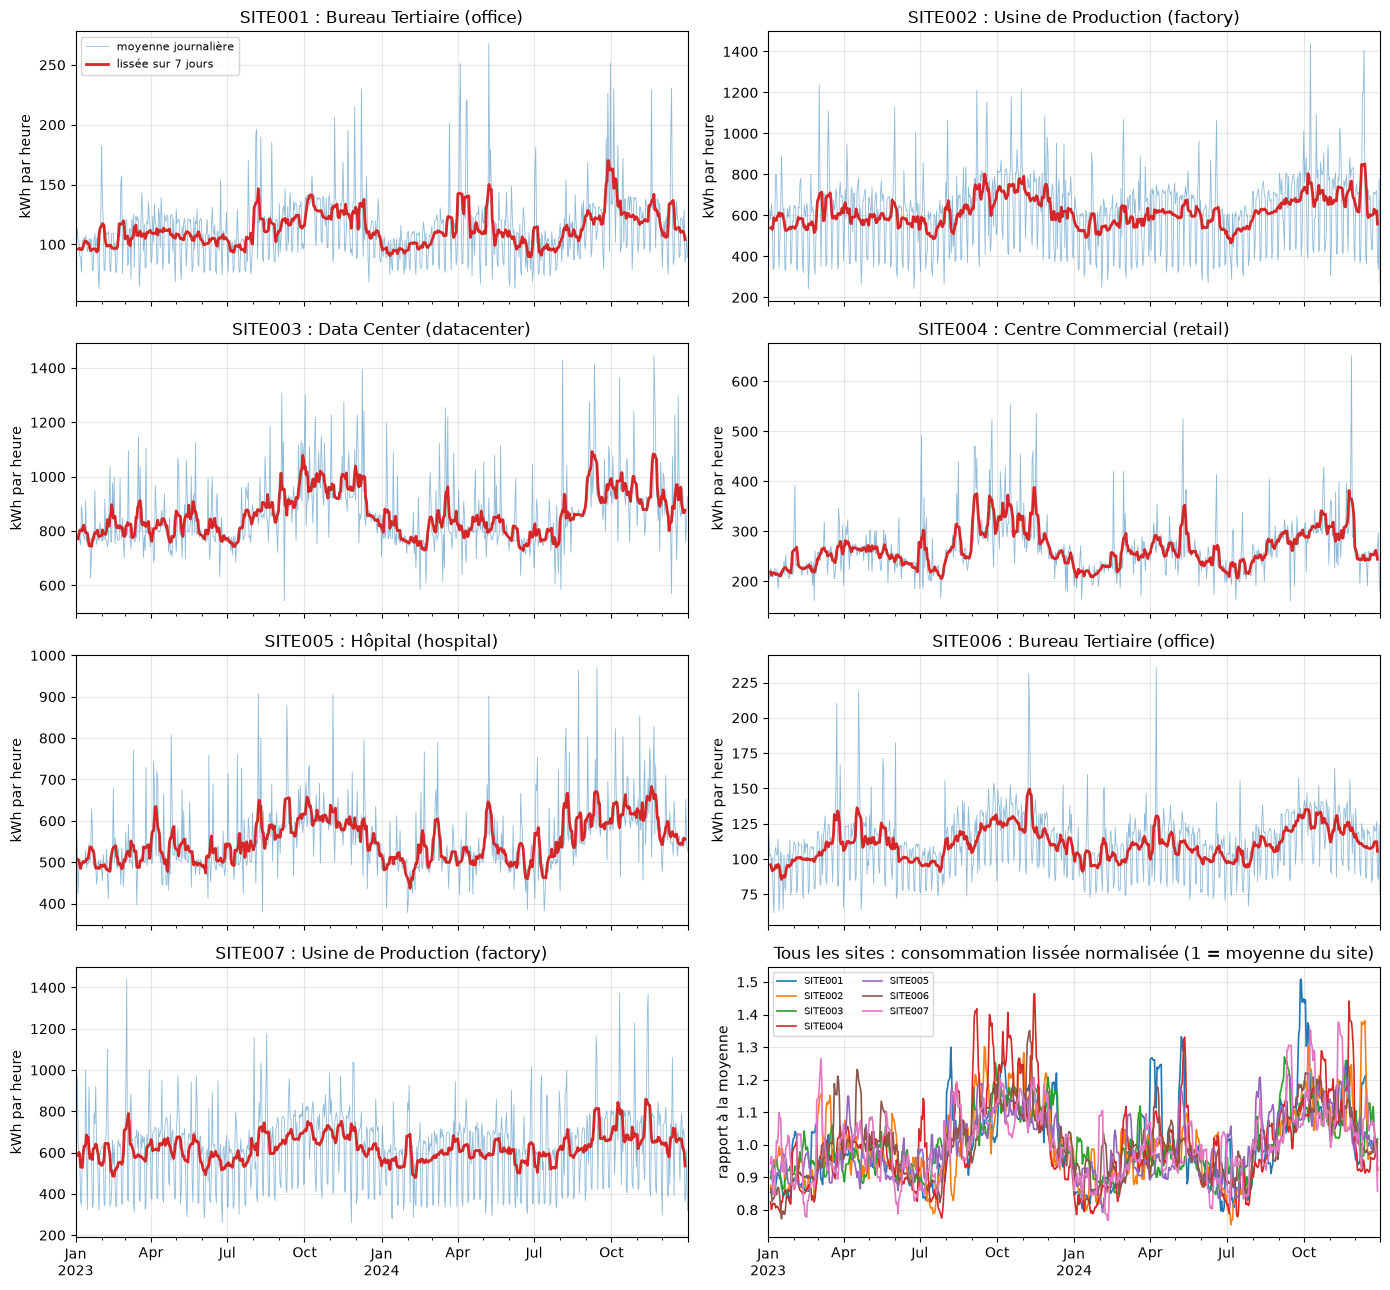

In [9]:
# Consommation moyenne par jour pour chaque site, sur la période DEBUT -> FIN
periode = df[(df["timestamp"] >= DEBUT) & (df["timestamp"] <= FIN)]
jour = (periode.pivot_table(index="timestamp", columns="site_id", values="consumption_kwh")
               .resample("D").mean())
lisse = jour.rolling(7, center=True).mean()       # moyenne glissante sur 7 jours

fiche = df.groupby("site_id")[["site_name", "site_type"]].first()   # pour les titres

# a) un graphique par site (bleu : moyenne journalière, rouge : lissée sur 7 jours)
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharex=True)
for ax, site in zip(axes.flat, jour.columns):
    ax.plot(jour.index, jour[site], lw=0.6, alpha=0.5, color="tab:blue", label="moyenne journalière")
    ax.plot(lisse.index, lisse[site], lw=2, color="tab:red", label="lissée sur 7 jours")
    ax.set(title=f"{site} : {fiche.loc[site, 'site_name']} ({fiche.loc[site, 'site_type']})",
           ylabel="kWh par heure")
axes.flat[0].legend(fontsize=8)

# b) dernier emplacement : tous les sites ensemble, normalisés (1 = moyenne du site) pour comparer les formes
ax = axes.flat[len(jour.columns)]
(lisse / lisse.mean()).plot(ax=ax, lw=1.2)
ax.set(title="Tous les sites : consommation lissée normalisée (1 = moyenne du site)", xlabel="", ylabel="rapport à la moyenne")
ax.legend(ncol=2, fontsize=7)

for ax in axes.flat[len(jour.columns) + 1:]:      # cases inutilisées
    ax.axis("off")

plt.tight_layout()
plt.show()

Ce que ça montre :
- Une saisonnalité commune sur l'ensemble des sites, la consommation est plus haute de septembre à novembre. La case en bas à droite confirme que les sites suivent la même forme
- Les sites sont de tailles différentes
- Les sites ne sont pas tous aussi réguliers, les data center et hôpital sont moins marqué, leur consommation dépend peu du jour de la semaines --> hypothèse : contrairement aux usines et bureaux, les hopitaux et data centers ne sont jamais fermés

## 5. Les rythmes de consommation (heure, jour, saison)

Compare les données de consommation selon le jour (si c'est en semaine ou en week end)

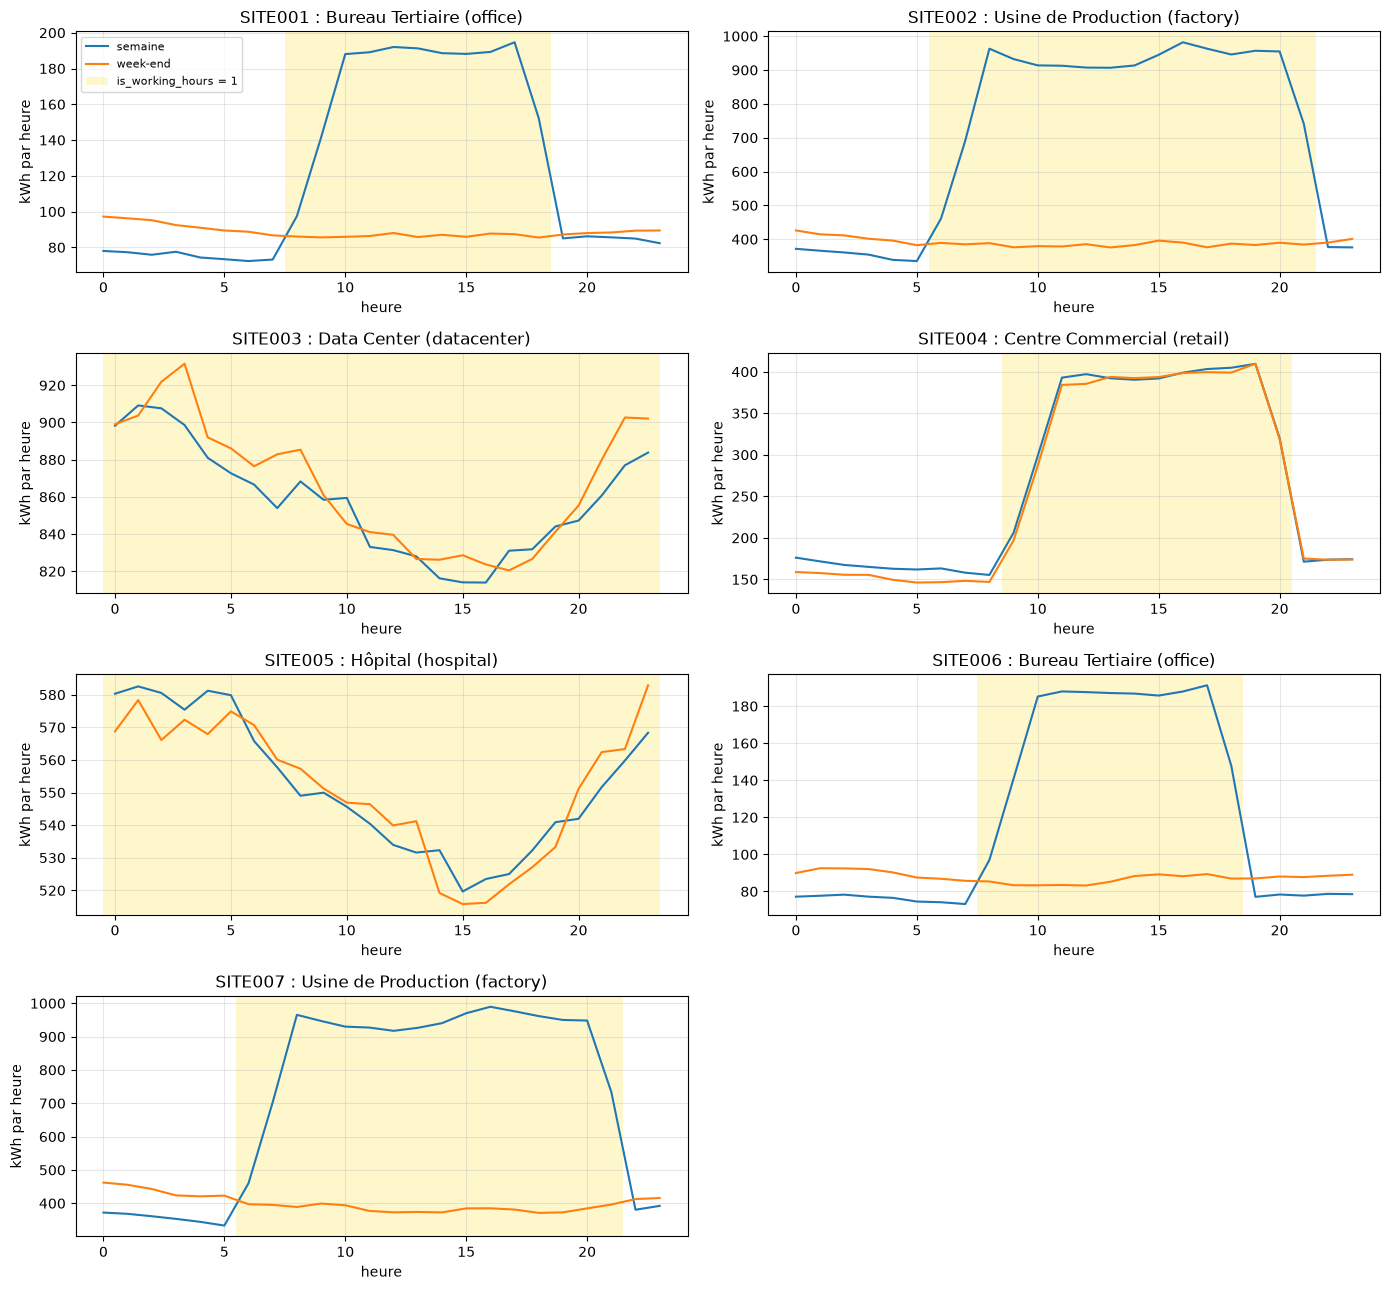

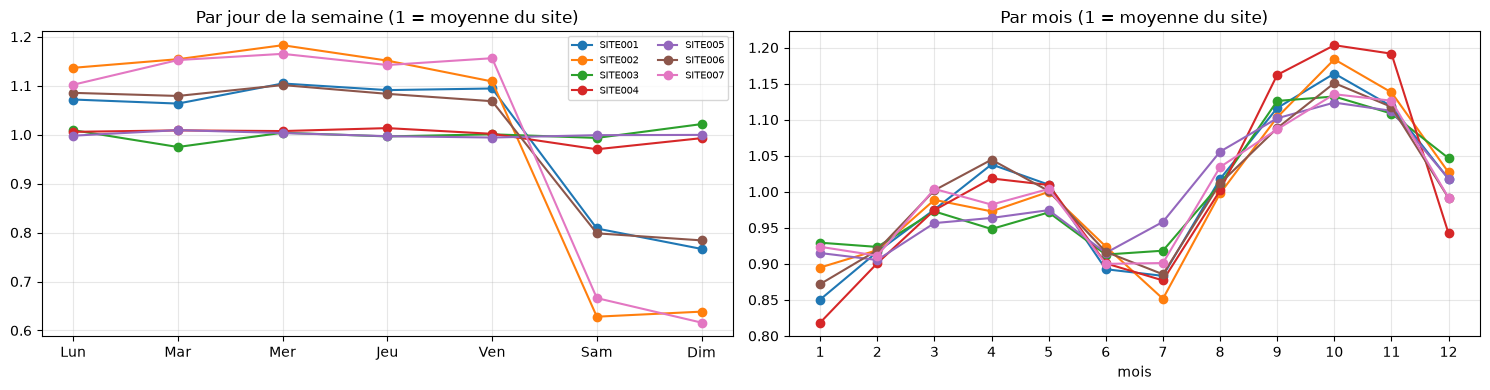

In [10]:
jours = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
jours_fr = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
fiche = df.groupby("site_id")[["site_name", "site_type"]].first()

# a) profil sur 24 h (semaine vs week-end), un graphique par site
#    zone dorée = heures où is_working_hours = 1 pour ce site
fig, axes = plt.subplots(4, 2, figsize=(14, 13))
for ax, (site, g) in zip(axes.flat, df.groupby("site_id")):
    profil = g.groupby(["is_weekend", "hour"])["consumption_kwh"].mean().unstack(0)
    profil.columns = ["semaine" if c == 0 else "week-end" for c in profil.columns]
    profil.plot(ax=ax, legend=False)

    h_travail = sorted(g.loc[g["is_working_hours"] == 1, "hour"].unique())
    for h in h_travail:
        ax.axvspan(h - 0.5, h + 0.5, color="gold", alpha=0.2, lw=0,
                   label="is_working_hours = 1" if h == h_travail[0] else None)
    ax.set(title=f"{site} : {fiche.loc[site, 'site_name']} ({fiche.loc[site, 'site_type']})",
           xlabel="heure", ylabel="kWh par heure")
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis("off")          # 8e case inutilisée
plt.tight_layout()
plt.show()

# b) et c) jour de la semaine et mois, tous les sites ensemble
#    (normalisés : 1 = consommation moyenne du site, pour comparer des sites de tailles différentes)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

par_jour = df.groupby(["day_name", "site_id"])["consumption_kwh"].mean().unstack().reindex(jours)
(par_jour / par_jour.mean()).plot(ax=axes[0], marker="o", title="Par jour de la semaine (1 = moyenne du site)")
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(jours_fr)
axes[0].set_xlabel("")
axes[0].legend(ncol=2, fontsize=7)

par_mois = df.groupby(["month", "site_id"])["consumption_kwh"].mean().unstack()
(par_mois / par_mois.mean()).plot(ax=axes[1], marker="o", title="Par mois (1 = moyenne du site)", legend=False)
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("mois")

plt.tight_layout()
plt.show()

Le graphique du dessus permet de comparer la consommation de chaque site à ses propres habitudes. On compare les rythmes de sites de tailles différentes pour voir quels sites semble avoir la meme habitude.

Ça ne montre pas quel site consomme le plus

### Vérifie les possibles incohérence entre la date et le jour indiqué 

In [13]:
# Contrôle de cohérence des dates : chaque ligne est comparée à un calcul indépendant (formule de Zeller)
JOURS_ZELLER = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
JOURS_LUNDI0 = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def jour_zeller(annee, mois, jour):
    """Jour de la semaine d'une date (calendrier grégorien), sans datetime ni pandas."""
    if mois < 3:
        mois += 12
        annee -= 1
    K, J = annee % 100, annee // 100
    h = (jour + (13 * (mois + 1)) // 5 + K + K // 4 + J // 4 + 5 * J) % 7
    return JOURS_ZELLER[h]


def controle_dates(data):
    """Renvoie (résumé des tests, lignes incohérentes) pour un tableau avec les colonnes calendaires."""
    t = data["timestamp"]
    # jour de la semaine calculé une seule fois par date distincte, puis recopié sur chaque ligne
    jour_date = {d: jour_zeller(d.year, d.month, d.day) for d in t.dt.date.unique()}
    zeller = t.dt.date.map(jour_date)

    tests = pd.DataFrame({
        "day_name différent de Zeller": data["day_name"] != zeller,
        "day_of_week différent de Zeller": data["day_of_week"] != zeller.map(JOURS_LUNDI0.index),
        "is_weekend incohérent": data["is_weekend"] != zeller.isin(["Saturday", "Sunday"]).astype(int),
        "month différent du timestamp": data["month"] != t.dt.month,
        "hour différente du timestamp": data["hour"] != t.dt.hour,
        "timestamp pas à l'heure pile": (t.dt.minute != 0) | (t.dt.second != 0),
        "timestamp manquant": t.isna(),
    })
    resume = tests.sum().rename("nb de lignes").to_frame()

    # lignes concernées, avec ce qui ne va pas
    cols = ["timestamp", "site_id", "day_name", "day_of_week", "is_weekend", "month", "hour"]
    masque = tests.any(axis=1)
    mauvaises = data.loc[masque, cols].copy()
    mauvaises["jour attendu (Zeller)"] = zeller[masque]
    sous = tests[masque]
    mauvaises["problèmes"] = [", ".join(sous.columns[ligne]) for ligne in sous.to_numpy()]
    return resume, mauvaises


resume, mauvaises = controle_dates(df)
print(f"{len(df):,} lignes contrôlées")
display(resume)
print(f"Lignes incohérentes : {len(mauvaises)}")
if len(mauvaises):
    display(mauvaises.head(20))

# --- Le contrôle est-il fiable ? On injecte volontairement 3 erreurs dans une copie ---
test = df.copy()
test.loc[10, "day_name"] = "Monday"          # le 1er janvier 2023 deviendrait un lundi
test.loc[500, "is_weekend"] = 1 - test.loc[500, "is_weekend"]
test.loc[900, "hour"] = (test.loc[900, "hour"] + 1) % 24
_, detectees = controle_dates(test)
print(f"\nTest du contrôle : 3 erreurs injectées, {len(detectees)} lignes détectées")
display(detectees[["timestamp", "site_id", "problèmes"]])

# --- Calendrier : trous, doublons, jours incomplets, pour chaque site ---
lignes = []
for site, g in df.groupby("site_id"):
    attendu = pd.date_range(g["timestamp"].min(), g["timestamp"].max(), freq="h")
    par_jour = g.groupby(g["timestamp"].dt.date).size()
    incomplets = par_jour[par_jour != 24]
    lignes.append({
        "site": site,
        "début": g["timestamp"].min(),
        "fin": g["timestamp"].max(),
        "heures manquantes": len(attendu.difference(g["timestamp"])),
        "doublons": int(g["timestamp"].duplicated().sum()),
        "jours avec moins ou plus de 24 lignes": ", ".join(f"{d} ({n})" for d, n in incomplets.items()) or "aucun",
    })
display(pd.DataFrame(lignes).set_index("site"))

# 29 février 2024 : bien présent (année bissextile) ?
bissextile = df[(df["timestamp"] >= "2024-02-29") & (df["timestamp"] < "2024-03-01")]
print(f"Lignes le 29/02/2024 : {len(bissextile)} (attendu : 24 par site x {df['site_id'].nunique()} sites = {24 * df['site_id'].nunique()})")

122,647 lignes contrôlées


,nb de lignes
day_name différent de Zeller,0
day_of_week différent de Zeller,0
is_weekend incohérent,0
month différent du timestamp,0
hour différente du timestamp,0
timestamp pas à l'heure pile,0
timestamp manquant,0


Lignes incohérentes : 0

Test du contrôle : 3 erreurs injectées, 3 lignes détectées


,timestamp,site_id,problèmes
10,2023-01-01 10:00:00,SITE001,day_name différent de Zeller
500,2023-01-21 20:00:00,SITE001,is_weekend incohérent
900,2023-02-07 12:00:00,SITE001,hour différente du timestamp


,début,fin,heures manquantes,doublons,jours avec moins ou plus de 24 lignes
site,,,,,
SITE001,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE002,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE003,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE004,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE005,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE006,2023-01-01,2024-12-31,0,0,2024-12-31 (1)
SITE007,2023-01-01,2024-12-31,0,0,2024-12-31 (1)


Lignes le 29/02/2024 : 168 (attendu : 24 par site x 7 sites = 168)


## 6. Comparer les sites

,type,nom,moyenne_kwh,mediane_kwh,max_kwh,total_GWh,cout_k_euros,pct_nuls,max / moyenne
site_id,,,,,,,,,
SITE001,office,Bureau Tertiaire,112.74,86.74,1006.26,1.93,290.12,2.35,8.9
SITE002,factory,Usine de Production,616.65,479.06,3225.29,10.55,1588.31,2.32,5.2
SITE003,datacenter,Data Center,860.31,826.50,2734.88,14.72,2215.07,2.32,3.2
SITE004,retail,Centre Commercial,265.03,209.32,1854.34,4.54,682.15,2.31,7.0
SITE005,hospital,Hôpital,551.86,528.79,2471.61,9.44,1420.87,2.33,4.5
SITE006,office,Bureau Tertiaire,110.73,86.52,595.84,1.90,285.23,2.27,5.4
SITE007,factory,Usine de Production,623.99,474.76,4599.76,10.68,1607.42,2.30,7.4


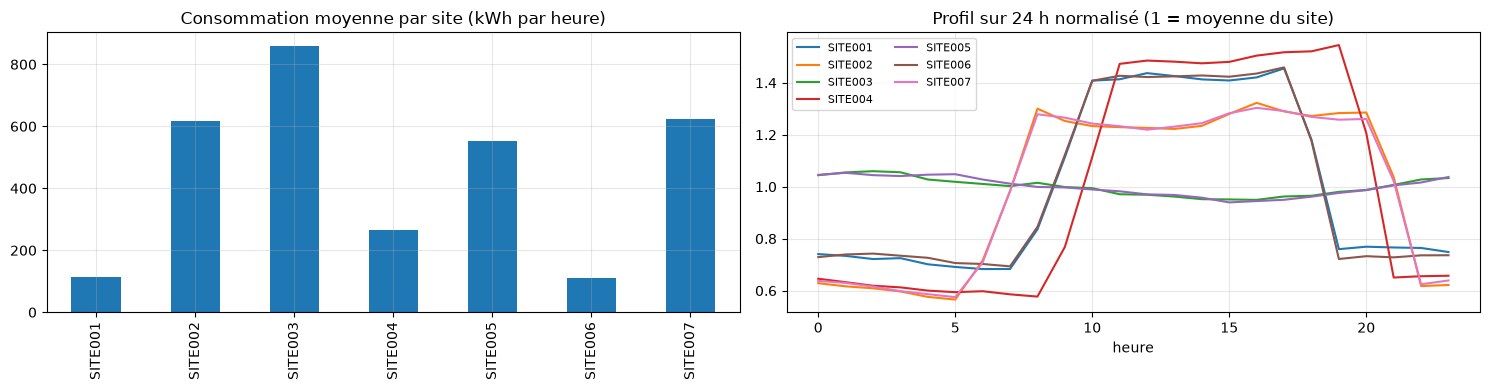

In [14]:
resume = df.groupby("site_id").agg(
    type=("site_type", "first"),
    nom=("site_name", "first"),
    moyenne_kwh=("consumption_kwh", "mean"),
    mediane_kwh=("consumption_kwh", "median"),
    max_kwh=("consumption_kwh", "max"),
    total_GWh=("consumption_kwh", lambda x: x.sum() / 1e6),
    cout_k_euros=("consumption_euros", lambda x: x.sum() / 1e3),
    pct_nuls=("consumption_kwh", lambda x: x.isna().mean() * 100),
).round(2)
resume["max / moyenne"] = (resume["max_kwh"] / resume["moyenne_kwh"]).round(1)
display(resume)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
resume["moyenne_kwh"].plot.bar(ax=axes[0], title="Consommation moyenne par site (kWh par heure)")
axes[0].set(xlabel="")

# Forme du profil sur 24 h, indépendamment de la taille du site (1 = moyenne du site)
prof = df.groupby(["site_id", "hour"])["consumption_kwh"].mean().unstack(0)
(prof / prof.mean()).plot(ax=axes[1], title="Profil sur 24 h normalisé (1 = moyenne du site)")
axes[1].set(xlabel="heure")
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()